# Part 3: crop type from ground photos, and photo vs satellite on the same farms

Data: ground photos taken by the enumerators of the 2023 Fezzan agriculture assessment.
- `survey`: photos of single-crop farms, label = crop reported in the survey, kept after the Assignment 2 screening (3 classes).
- `hand`: photos of the remaining farms, sorted by hand into the 4 classes by looking at the photo.

Test set: photos within 600 m (chained) of a satellite test farm, so the photo and satellite test sets cover the same places.
Development set: 5 folds grouped by location.

Sections: 0 setup · 1 data and splits · 2 helpers · 3 CNN from scratch (P0-P1) · 4 transfer learning (P2-P5) · 5 test set · 6 photo vs satellite on the same farms · 7 downstream use · 8 save model.

Rule: one change per model; a change is kept only if the pooled out-of-fold macro-F1 on the development set goes up.

## 0. Setup

In [1]:
import os, time, json, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf, keras
from keras import layers
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, roc_auc_score, log_loss)
SEED = 42; keras.utils.set_random_seed(SEED)
DATA = "data"; FAST = os.environ.get("FAST") == "1"
OUT = "outputs_smoke" if FAST else "outputs"; os.makedirs(OUT, exist_ok=True)
WEIGHTS_DIR = "weights"
CLASSES = ["alfalfa", "cereals", "palm", "palm_orchard"]; N = len(CLASSES)
COLORS = ["#2b6cb0", "#d98a00", "#1f7a5a", "#b03a3a"]
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

I0000 00:00:1795609355.086191    2389 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795609355.086687    2389 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1795609356.509146    2389 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795609356.509589    2389 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | Keras 3.15.1


## 1. Data and splits

In [2]:
idx = pd.read_csv(f"{DATA}/photos_index.csv")
if FAST: idx = idx.groupby(["label", "split"]).head(25).reset_index(drop=True)
idx["y"] = idx.label.map(CLASSES.index); y = idx.y.to_numpy(dtype=np.int64)
display(pd.crosstab([idx.source, idx.label], idx.split, margins=True))

DEV = np.where(idx.split == "dev")[0]; TEST = np.where(idx.split == "test")[0]
fold = np.full(len(idx), -1)
for k, (_, va) in enumerate(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(DEV, y[DEV], idx.group.values[DEV])):
    fold[DEV[va]] = k
idx["fold"] = fold
assert not set(idx.group[idx.split == "test"]) & set(idx.group[idx.split == "dev"])
for k in range(5): assert not set(idx.group[idx.fold == k]) & set(idx.group[(idx.fold != k) & (idx.split == "dev")])
display(pd.crosstab(idx.label, idx.fold.map(lambda k: f"fold {k + 1}" if k >= 0 else "test")))
maj = np.bincount(y[DEV]).argmax()
print(f"baseline (always '{CLASSES[maj]}'): dev accuracy {np.mean(y[DEV] == maj):.3f} | test accuracy {np.mean(y[TEST] == maj):.3f} | test macro-F1 {f1_score(y[TEST], np.full(len(TEST), maj), average='macro'):.3f}")

split                dev  test  All
source label                       
hand   alfalfa        76    27  103
       cereals        60    15   75
       palm           41     8   49
       palm_orchard   94    51  145
survey alfalfa        51    13   64
       cereals        29    21   50
       palm           44    27   71
All                  395   162  557

fold,fold 1,fold 2,fold 3,fold 4,fold 5,test
label,,,,,,
alfalfa,25,26,25,26,25,40
cereals,18,19,17,17,18,36
palm,17,17,17,17,17,35
palm_orchard,19,20,19,18,18,51


baseline (always 'alfalfa'): dev accuracy 0.322 | test accuracy 0.247 | test macro-F1 0.099


(557, 224, 224, 3) (557, 128, 128, 3)


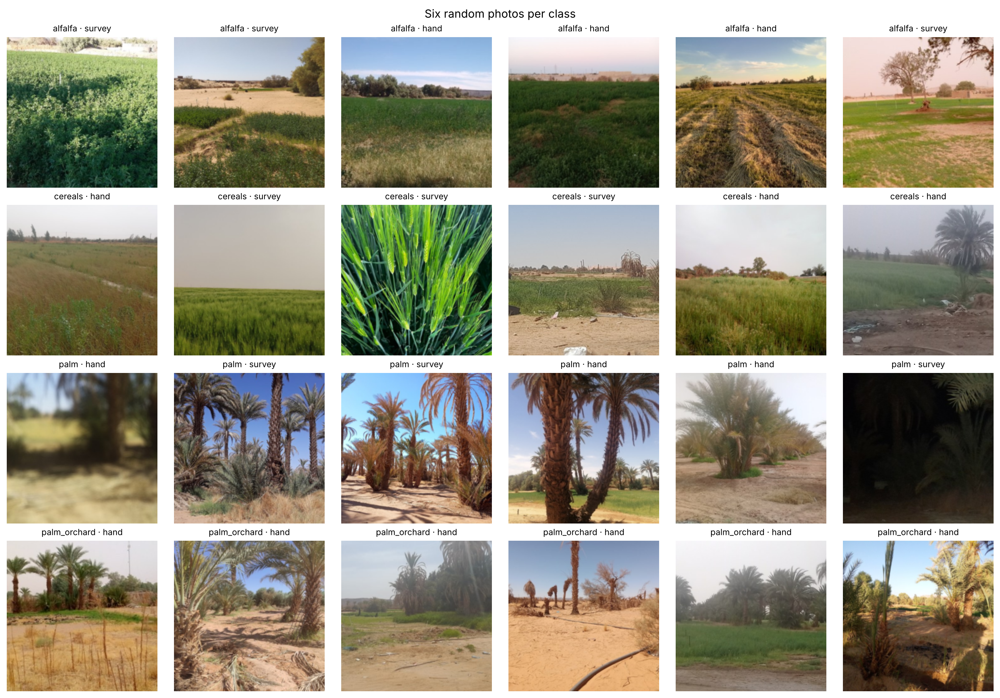

In [3]:
def load(path, px):
    """Shorter side to px, then centre square crop (photos are 4:3)."""
    im = Image.open(f"{DATA}/{path}").convert("RGB"); w, h = im.size; s = px / min(w, h)
    im = im.resize((round(w * s), round(h * s)), Image.BILINEAR); w, h = im.size; l, t = (w - px) // 2, (h - px) // 2
    return np.asarray(im.crop((l, t, l + px, t + px)), dtype=np.uint8)
X224 = np.stack([load(p, 224) for p in idx.image]); X128 = np.stack([load(p, 128) for p in idx.image])
print(X224.shape, X128.shape)
fig, ax = plt.subplots(4, 6, figsize=(15, 10.5))
for r, c in enumerate(CLASSES):
    for j, i in enumerate(idx[idx.label == c].sample(6, random_state=1).index):
        ax[r, j].imshow(X224[i]); ax[r, j].set_title(f"{c} · {idx.source[i]}", fontsize=9); ax[r, j].axis("off")
plt.suptitle("Six random photos per class"); plt.tight_layout(); plt.savefig(f"{OUT}/photo_samples.png", dpi=100); plt.show()

## 2. Helpers

In [4]:
RESULTS, OOF, HIST = [], {}, {}
def per_class_recall(yt, yp): return [float(np.mean(yp[yt == c] == c)) if np.any(yt == c) else np.nan for c in range(N)]
def score(name, change, P, extra=None):
    yt = y[DEV]; yp = P.argmax(1)
    row = {"model": name, "change": change, "val acc": accuracy_score(yt, yp), "val macro-F1": f1_score(yt, yp, average="macro"),
           "val log loss": log_loss(yt, np.clip(P, 1e-7, 1), labels=range(N))}
    row.update({f"recall {c}": r for c, r in zip(CLASSES, per_class_recall(yt, yp))}); row.update(extra or {})
    RESULTS.append(row); OOF[name] = P
    print(f"{name}: {change}\n  val acc {row['val acc']:.3f} | macro-F1 {row['val macro-F1']:.3f} | log loss {row['val log loss']:.3f}")
    print("  recall per class:", {c: round(r, 2) for c, r in zip(CLASSES, per_class_recall(yt, yp))}); return row
def table(names=None):
    t = pd.DataFrame(RESULTS).set_index("model"); return (t.loc[names] if names else t).round(3)
def better(new, old): return new["val macro-F1"] > old["val macro-F1"]
class PerClass(keras.callbacks.Callback):
    def __init__(self, Xv, yv): super().__init__(); self.Xv, self.yv, self.v = Xv, yv, []
    def on_epoch_end(self, epoch, logs=None): self.v.append(per_class_recall(self.yv, self.model.predict(self.Xv, verbose=0).argmax(1)))
def plot_curves(name):
    h = HIST[name]; e = range(1, len(h["loss"]) + 1); best = int(np.argmin(h["val_loss"])) + 1
    fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
    for a, m in zip(ax[:2], ["accuracy", "loss"]):
        a.plot(e, h[m], label="train"); a.plot(e, h["val_" + m], label="validation"); a.axvline(best, ls=":", c="gray"); a.set_title(f"{name}: {m} (fold 1)"); a.set_xlabel("epoch"); a.legend()
    pc = np.array(h["per_class"])
    for c in range(N): ax[2].plot(e, pc[:, c], c=COLORS[c], label=CLASSES[c])
    ax[2].axvline(best, ls=":", c="gray"); ax[2].set_ylim(0, 1); ax[2].set_title("validation recall per class (fold 1)"); ax[2].set_xlabel("epoch"); ax[2].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f"{OUT}/photo_curves_{name}.png", dpi=100); plt.show()

## 3. CNN from scratch (128 px)

In [5]:
def make_ds(X, yy, train, bs=32):
    ds = tf.data.Dataset.from_tensor_slices((X, yy))
    if train: ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(bs).prefetch(tf.data.AUTOTUNE)
def build_cnn(filters=(32, 64, 128), augment=False, px=128):
    keras.utils.set_random_seed(SEED)
    inp = keras.Input((px, px, 3)); x = layers.RandomFlip("horizontal")(inp) if augment else inp   # photos have an 'up': flip left-right only
    x = layers.Rescaling(1 / 255)(x)
    for f in filters:
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x); x = layers.BatchNormalization(momentum=0.9)(x)
        x = layers.Activation("relu")(x); x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    return keras.Model(inp, layers.Dense(N, activation="softmax")(x))
def run_cnn(name, change, max_epochs=40, patience=8, **kw):
    max_epochs = 2 if FAST else max_epochs; P = np.zeros((len(DEV), N)); epochs = []; t = time.time()
    for k in range(5):
        tr = DEV[fold[DEV] != k]; va = DEV[fold[DEV] == k]
        m = build_cnn(**kw); m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        cb = [keras.callbacks.EarlyStopping("val_loss", patience=patience, restore_best_weights=True)]
        if k == 0: pcb = PerClass(X128[va], y[va]); cb.append(pcb)
        h = m.fit(make_ds(X128[tr], y[tr], True), validation_data=make_ds(X128[va], y[va], False), epochs=max_epochs, callbacks=cb, verbose=0).history
        if k == 0: HIST[name] = {**h, "per_class": pcb.v}
        P[np.searchsorted(DEV, va)] = m.predict(X128[va], verbose=0); epochs.append(int(np.argmin(h["val_loss"])) + 1)
    row = score(name, change, P, {"weights": m.count_params(), "best epochs": epochs, "time (s)": round(time.time() - t)}); plot_curves(name); return row

P0: 3 conv blocks (32-64-128) + batch norm, 128 px, Adam 0.001
  val acc 0.529 | macro-F1 0.521 | log loss 1.030
  recall per class: {'alfalfa': 0.65, 'cereals': 0.4, 'palm': 0.53, 'palm_orchard': 0.48}


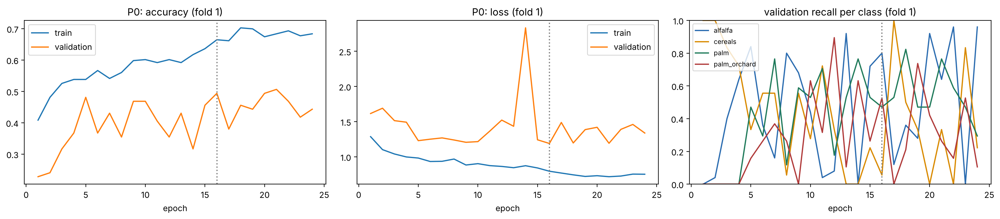

In [6]:
cnn_cfg = dict(augment=False)
p0 = run_cnn("P0", "3 conv blocks (32-64-128) + batch norm, 128 px, Adam 0.001", **cnn_cfg); best_s, best_s_row = "P0", p0

P1: P0 + random left-right flips
  val acc 0.516 | macro-F1 0.505 | log loss 1.031
  recall per class: {'alfalfa': 0.65, 'cereals': 0.33, 'palm': 0.6, 'palm_orchard': 0.44}


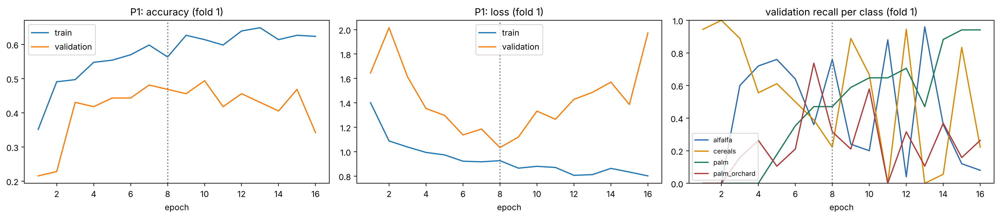

final CNN from scratch: P0 {'augment': False}


In [7]:
p1 = run_cnn("P1", "P0 + random left-right flips", augment=True)
if better(p1, best_s_row): cnn_cfg["augment"] = True; best_s, best_s_row = "P1", p1
print("final CNN from scratch:", best_s, cnn_cfg)

## 4. Transfer learning (frozen ImageNet backbones)

In [8]:
BACKBONES = {
    "resnet50": (keras.applications.ResNet50, keras.applications.resnet50.preprocess_input, "resnet50_weights_tf_dim_ordering_tf_kernels_notop.h5"),
    "densenet121": (keras.applications.DenseNet121, keras.applications.densenet.preprocess_input, "densenet121_weights_tf_dim_ordering_tf_kernels_notop.h5"),
}
def backbone(name):
    fn, pre, wfile = BACKBONES[name]; local = os.path.join(WEIGHTS_DIR, wfile)
    m = fn(include_top=False, weights=None if os.path.exists(local) else "imagenet", input_shape=(224, 224, 3), pooling="avg")
    if os.path.exists(local): m.load_weights(local)
    return m, pre
def features(name):
    """Pooled features of each photo and of its left-right mirror -> (2, n, d). Cached."""
    path = f"{OUT}/photo_features_{name}.npy"
    if os.path.exists(path) and np.load(path).shape[1] == len(idx): return np.load(path)
    m, pre = backbone(name)
    F = np.stack([m.predict(pre(X.astype("float32")), batch_size=32, verbose=0) for X in (X224, X224[:, :, ::-1])]); np.save(path, F); return F
def lr_head(): return make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=5000))
def run_lr(name, change, F, flips=False):
    P = np.zeros((len(DEV), N)); R = range(2) if flips else range(1)
    for k in range(5):
        tr = DEV[fold[DEV] != k]; va = DEV[fold[DEV] == k]
        clf = lr_head().fit(np.concatenate([F[r][tr] for r in R]), np.tile(y[tr], len(R)))
        P[np.searchsorted(DEV, va)] = np.mean([clf.predict_proba(F[r][va]) for r in R], axis=0)
    return score(name, change, P, {"weights": (F.shape[2] + 1) * N})

In [9]:
tl = dict(backbone="resnet50", flips=False, head="logistic")
p2 = run_lr("P2", "ResNet50 frozen, logistic regression head", features("resnet50")); best_t, best_t_row = "P2", p2

P2: ResNet50 frozen, logistic regression head
  val acc 0.678 | macro-F1 0.673 | log loss 0.854
  recall per class: {'alfalfa': 0.73, 'cereals': 0.63, 'palm': 0.69, 'palm_orchard': 0.64}


In [10]:
p3 = run_lr("P3", "P2 with DenseNet121 in place of ResNet50", features("densenet121"))
if better(p3, best_t_row): tl["backbone"] = "densenet121"; best_t, best_t_row = "P3", p3
print("kept:", best_t)

P3: P2 with DenseNet121 in place of ResNet50
  val acc 0.656 | macro-F1 0.647 | log loss 0.951
  recall per class: {'alfalfa': 0.75, 'cereals': 0.57, 'palm': 0.69, 'palm_orchard': 0.57}
kept: P2


In [11]:
p4 = run_lr("P4", f"{best_t} + left-right mirror (train on both, average both)", features(tl["backbone"]), flips=True)
if better(p4, best_t_row): tl["flips"] = True; best_t, best_t_row = "P4", p4
print("kept:", best_t)

P4: P2 + left-right mirror (train on both, average both)
  val acc 0.696 | macro-F1 0.690 | log loss 0.895
  recall per class: {'alfalfa': 0.76, 'cereals': 0.65, 'palm': 0.68, 'palm_orchard': 0.67}
kept: P4


P5: P4 with a dense head (256 units, dropout 0.4) in place of logistic regression
  val acc 0.673 | macro-F1 0.666 | log loss 1.045
  recall per class: {'alfalfa': 0.74, 'cereals': 0.63, 'palm': 0.72, 'palm_orchard': 0.59}


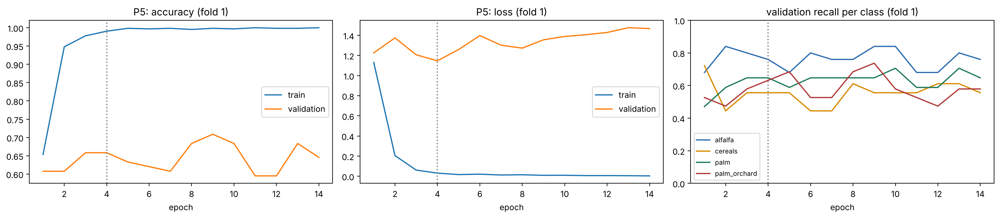

final transfer model: P4 {'backbone': 'resnet50', 'flips': True, 'head': 'logistic'}


,change,val acc,val macro-F1,val log loss,recall alfalfa,recall cereals,recall palm,recall palm_orchard,weights,best epochs,time (s)
model,,,,,,,,,,,
P0,"3 conv blocks (32-64-128) + batch norm, 128 px...",0.529,0.521,1.030,0.654,0.404,0.529,0.479,94436,"[16, 28, 13, 9, 25]",528.0
P1,P0 + random left-right flips,0.516,0.505,1.031,0.654,0.326,0.600,0.436,94436,"[8, 6, 20, 9, 10]",385.0
P2,"ResNet50 frozen, logistic regression head",0.678,0.673,0.854,0.732,0.629,0.694,0.638,8196,NaN,NaN
P3,P2 with DenseNet121 in place of ResNet50,0.656,0.647,0.951,0.748,0.573,0.694,0.574,4100,NaN,NaN
P4,"P2 + left-right mirror (train on both, average...",0.696,0.690,0.895,0.756,0.652,0.682,0.670,8196,NaN,NaN
P5,"P4 with a dense head (256 units, dropout 0.4) ...",0.673,0.666,1.045,0.740,0.629,0.718,0.585,525572,"[4, 1, 3, 1, 1]",NaN


In [12]:
def dense_head(d):
    keras.utils.set_random_seed(SEED)
    inp = keras.Input((d,)); x = layers.Dense(256, activation="relu")(inp); x = layers.Dropout(0.4)(x)
    return keras.Model(inp, layers.Dense(N, activation="softmax")(x))
def run_dense(name, change, F, flips, max_epochs=100, patience=10):
    max_epochs = 2 if FAST else max_epochs; P = np.zeros((len(DEV), N)); epochs = []
    mu, sd = F[0][DEV].mean(0), F[0][DEV].std(0) + 1e-6; Fz = (F - mu) / sd; R = range(2) if flips else range(1)
    for k in range(5):
        tr = DEV[fold[DEV] != k]; va = DEV[fold[DEV] == k]
        m = dense_head(F.shape[2]); m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        cb = [keras.callbacks.EarlyStopping("val_loss", patience=patience, restore_best_weights=True)]
        if k == 0: pcb = PerClass(Fz[0][va], y[va]); cb.append(pcb)
        h = m.fit(np.concatenate([Fz[r][tr] for r in R]), np.tile(y[tr], len(R)), validation_data=(Fz[0][va], y[va]), epochs=max_epochs, batch_size=32, callbacks=cb, verbose=0).history
        if k == 0: HIST[name] = {**h, "per_class": pcb.v}
        P[np.searchsorted(DEV, va)] = np.mean([m.predict(Fz[r][va], verbose=0) for r in R], axis=0); epochs.append(int(np.argmin(h["val_loss"])) + 1)
    row = score(name, change, P, {"weights": m.count_params(), "best epochs": epochs}); plot_curves(name); return row
p5 = run_dense("P5", f"{best_t} with a dense head (256 units, dropout 0.4) in place of logistic regression", features(tl["backbone"]), tl["flips"])
if better(p5, best_t_row): tl["head"] = "dense"; best_t, best_t_row = "P5", p5
print("final transfer model:", best_t, tl); display(table()); table().to_csv(f"{OUT}/photo_experiments.csv")

In [13]:
# Does the model do equally well on both label sources? (development set, out-of-fold, final transfer model)
P = OOF[best_t]; yp = P.argmax(1); src = idx.source.values[DEV]
for s in ["survey", "hand"]:
    m_ = src == s; print(f"{s:6s}: {m_.sum()} photos | acc {accuracy_score(y[DEV][m_], yp[m_]):.3f} | macro-F1 {f1_score(y[DEV][m_], yp[m_], average='macro'):.3f}",
                        "| recall", {c: round(r, 2) for c, r in zip(CLASSES, per_class_recall(y[DEV][m_], yp[m_]))})

survey: 124 photos | acc 0.685 | macro-F1 0.543 | recall {'alfalfa': 0.71, 'cereals': 0.62, 'palm': 0.7, 'palm_orchard': nan}
hand  : 271 photos | acc 0.701 | macro-F1 0.687 | recall {'alfalfa': 0.79, 'cereals': 0.67, 'palm': 0.66, 'palm_orchard': 0.67}


## 5. Test set: final models trained on all development photos

In [14]:
ep = int(np.median(table().loc[best_s, "best epochs"]))
cnn = build_cnn(**cnn_cfg); cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.fit(make_ds(X128[DEV], y[DEV], True), epochs=ep, verbose=0); P_cnn = cnn.predict(X128[TEST], verbose=0)

F = features(tl["backbone"]); R = range(2) if tl["flips"] else range(1)
if tl["head"] == "logistic":
    head = lr_head().fit(np.concatenate([F[r][DEV] for r in R]), np.tile(y[DEV], len(R))); mu = sd = None
    P_tl = np.mean([head.predict_proba(F[r][TEST]) for r in R], axis=0)
else:
    mu, sd = F[0][DEV].mean(0), F[0][DEV].std(0) + 1e-6; Fz = (F - mu) / sd
    head = dense_head(F.shape[2]); head.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    head.fit(np.concatenate([Fz[r][DEV] for r in R]), np.tile(y[DEV], len(R)), epochs=int(np.median(table().loc[best_t, "best epochs"])), batch_size=32, verbose=0)
    P_tl = np.mean([head.predict(Fz[r][TEST], verbose=0) for r in R], axis=0)

yt = y[TEST]; maj_p = np.zeros((len(TEST), N)); maj_p[:, maj] = 1; summary = {}
for nm, P in [("baseline", maj_p), (f"CNN from scratch ({best_s})", P_cnn), (f"transfer ({best_t})", P_tl)]:
    summary[nm] = {"test photos": len(TEST), "accuracy": accuracy_score(yt, P.argmax(1)), "macro-F1": f1_score(yt, P.argmax(1), average="macro"),
                   "macro AUC (one-vs-rest)": roc_auc_score(yt, P, multi_class="ovr", average="macro") if nm != "baseline" else 0.5,
                   **{f"recall {c}": r for c, r in zip(CLASSES, per_class_recall(yt, P.argmax(1)))}}
summary = pd.DataFrame(summary).round(3); display(summary); summary.to_csv(f"{OUT}/photo_test_summary.csv")
for nm, P in [(f"CNN from scratch ({best_s})", P_cnn), (f"transfer ({best_t})", P_tl)]:
    print(nm); print(classification_report(yt, P.argmax(1), target_names=CLASSES, digits=3))
for s in ["survey", "hand"]:
    m_ = idx.source.values[TEST] == s; print(f"transfer, {s} photos: {m_.sum()} | acc {accuracy_score(yt[m_], P_tl.argmax(1)[m_]):.3f} | macro-F1 {f1_score(yt[m_], P_tl.argmax(1)[m_], average='macro'):.3f}")

,baseline,CNN from scratch (P0),transfer (P4)
test photos,162.000,162.000,162.000
accuracy,0.247,0.432,0.574
macro-F1,0.099,0.426,0.577
macro AUC (one-vs-rest),0.500,0.721,0.806
recall alfalfa,1.000,0.400,0.675
recall cereals,0.000,0.528,0.583
recall palm,0.000,0.771,0.543
recall palm_orchard,0.000,0.157,0.510


CNN from scratch (P0)
              precision    recall  f1-score   support

     alfalfa      0.696     0.400     0.508        40
     cereals      0.463     0.528     0.494        36
        palm      0.338     0.771     0.470        35
palm_orchard      0.444     0.157     0.232        51

    accuracy                          0.432       162
   macro avg      0.485     0.464     0.426       162
weighted avg      0.488     0.432     0.410       162

transfer (P4)
              precision    recall  f1-score   support

     alfalfa      0.614     0.675     0.643        40
     cereals      0.700     0.583     0.636        36
        palm      0.463     0.543     0.500        35
palm_orchard      0.553     0.510     0.531        51

    accuracy                          0.574       162
   macro avg      0.583     0.578     0.577       162
weighted avg      0.581     0.574     0.575       162

transfer, survey photos: 61 | acc 0.656 | macro-F1 0.543
transfer, hand photos: 101 | acc 0.52

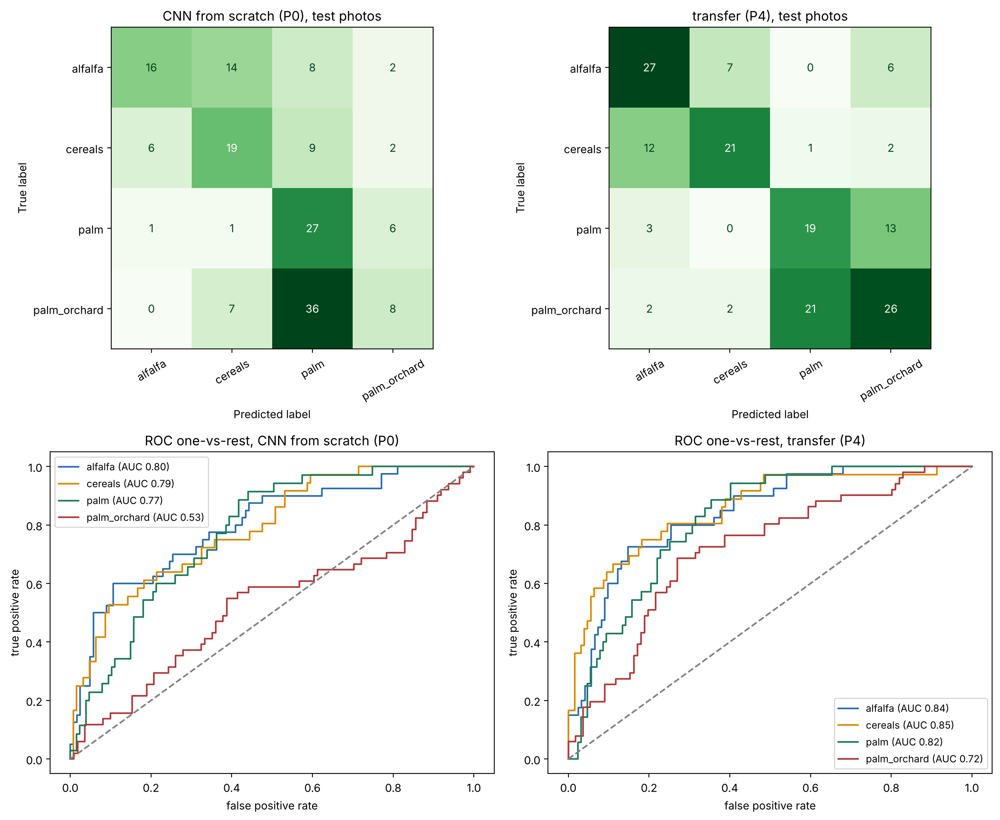

test photos: 162 | macro-F1 transfer minus scratch +0.151, 95% interval +0.061 to +0.245


In [15]:
fig, ax = plt.subplots(2, 2, figsize=(13, 10.5))
for j, (nm, P) in enumerate([(f"CNN from scratch ({best_s})", P_cnn), (f"transfer ({best_t})", P_tl)]):
    ConfusionMatrixDisplay(confusion_matrix(yt, P.argmax(1), labels=range(N)), display_labels=CLASSES).plot(ax=ax[0, j], cmap="Greens", colorbar=False)
    ax[0, j].set_title(f"{nm}, test photos"); ax[0, j].tick_params(axis="x", rotation=30)
    for c in range(N):
        fpr, tpr, _ = roc_curve(yt == c, P[:, c]); ax[1, j].plot(fpr, tpr, c=COLORS[c], label=f"{CLASSES[c]} (AUC {roc_auc_score(yt == c, P[:, c]):.2f})")
    ax[1, j].plot([0, 1], [0, 1], ls="--", c="gray"); ax[1, j].set_title(f"ROC one-vs-rest, {nm}"); ax[1, j].set_xlabel("false positive rate"); ax[1, j].set_ylabel("true positive rate"); ax[1, j].legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT}/photo_test_confusion_roc.png", dpi=100); plt.show()

rng = np.random.default_rng(SEED); d = []
for _ in range(3000):
    s = rng.integers(0, len(yt), len(yt)); d.append(f1_score(yt[s], P_tl[s].argmax(1), average="macro") - f1_score(yt[s], P_cnn[s].argmax(1), average="macro"))
d = np.array(d); print(f"test photos: {len(yt)} | macro-F1 transfer minus scratch {np.mean(d):+.3f}, 95% interval {np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f}")

## 6. Photo vs satellite on the same test farms

Farms that have a test photo AND satellite views (2021+), where neither model saw the farm in training.
Satellite model = the part-1 final transfer model (trained on satellite development farms only). Fusion = average of the two probability vectors.

In [16]:
sat = pd.concat([pd.read_csv(f"{DATA}/chips_index.csv"), pd.read_csv(f"{DATA}/chips_index_batch3.csv")], ignore_index=True)
sat = sat[sat.year >= 2021]
# satellite development farms of part 1 (same split code and seed) must not be used here
s1 = pd.read_csv(f"{DATA}/chips_index.csv"); s1 = s1[s1.year >= 2021]; s1 = s1[~s1.farm.isin(set(pd.read_csv(f"{DATA}/conflicting_farms.csv").farm))].reset_index(drop=True)
fs = s1.drop_duplicates("farm").reset_index(drop=True); dv, _ = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(fs, fs.label.map(CLASSES.index), fs.cluster))
sat_dev = set(fs.farm[dv])
both = idx.iloc[TEST].assign(p=list(P_tl))
both = both[both.sat_farm.notna() & both.sat_farm.isin(set(sat.farm)) & ~both.sat_farm.isin(sat_dev)]
print("test photos with a usable satellite farm:", len(both), "| farms:", both.sat_farm.nunique())

SATM = "outputs/models"   # part-1 satellite model
cfg = json.load(open(f"{SATM}/config.json"))["transfer"]; m_sat, pre_sat = backbone(cfg["backbone"])
h_sat = keras.models.load_model(f"{SATM}/transfer_head.keras"); sc = np.load(f"{SATM}/transfer_scaler.npz")
def sat_probs(farm):
    ims = sat.image[sat.farm == farm]
    X = np.stack([np.asarray(Image.open(f"{DATA}/{p}").convert("RGB").resize((224, 224), Image.BILINEAR), dtype=np.uint8) for p in ims])
    return h_sat.predict((m_sat.predict(pre_sat(X.astype("float32")), verbose=0) - sc["mu"]) / sc["sd"], verbose=0).mean(0)
farm_rows = []
for f, g in both.groupby("sat_farm"):
    pp = np.mean(np.stack(g.p.values), axis=0); ps = sat_probs(f)
    farm_rows.append({"farm": f, "label": g.label.iloc[0], "source": g.source.iloc[0], "p_photo": pp, "p_sat": ps, "p_fused": (pp + ps) / 2})
H = pd.DataFrame(farm_rows); yh = H.label.map(CLASSES.index).values
h2h = {}
for nm, col in [("photo model", "p_photo"), ("satellite model", "p_sat"), ("photo + satellite (average)", "p_fused")]:
    P = np.stack(H[col].values); h2h[nm] = {"farms": len(H), "accuracy": accuracy_score(yh, P.argmax(1)), "macro-F1": f1_score(yh, P.argmax(1), average="macro", labels=range(N)),
                                             **{f"recall {c}": r for c, r in zip(CLASSES, per_class_recall(yh, P.argmax(1)))}}
h2h = pd.DataFrame(h2h).round(3); display(h2h); h2h.to_csv(f"{OUT}/photo_vs_satellite.csv")
print("farms per class:", H.label.value_counts().to_dict(), "| label source:", H.source.value_counts().to_dict())

test photos with a usable satellite farm: 138 | farms: 138


,photo model,satellite model,photo + satellite (average)
farms,138.000,138.000,138.000
accuracy,0.565,0.275,0.522
macro-F1,0.570,0.276,0.534
recall alfalfa,0.625,0.250,0.594
recall cereals,0.593,0.519,0.593
recall palm,0.516,0.452,0.548
recall palm_orchard,0.542,0.042,0.417


farms per class: {'palm_orchard': 48, 'alfalfa': 32, 'palm': 31, 'cereals': 27} | label source: {'hand': 94, 'survey': 44}


## 7. Downstream use: checking the reported crop while the enumerator is still at the farm

test photos: 162 | flagged: 48 (29.6%)
label         pred        
alfalfa       cereals          4
              palm_orchard     6
cereals       alfalfa          9
              palm_orchard     2
palm          alfalfa          2
              palm_orchard     8
palm_orchard  alfalfa          1
              cereals          2
              palm            14
dtype: int64


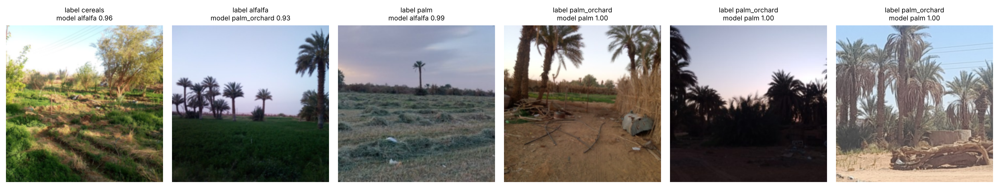

In [17]:
# For survey-labelled test photos: flag when the reported crop is very unlikely from the photo.
t = idx.iloc[TEST].assign(pred=[CLASSES[i] for i in P_tl.argmax(1)], p_pred=P_tl.max(1).round(3), p_reported=P_tl[np.arange(len(TEST)), yt].round(3))
t["flag"] = (t.p_reported < 0.15) & (t.p_pred >= 0.6)
print(f"test photos: {len(t)} | flagged: {t.flag.sum()} ({t.flag.mean():.1%})"); print(t[t.flag].groupby(["label", "pred"]).size())
t[["image", "label", "source", "pred", "p_pred", "p_reported", "flag"]].to_csv(f"{OUT}/photo_check_test.csv", index=False)
fl = t[t.flag].sort_values("p_reported").head(6)
if len(fl):
    fig, ax = plt.subplots(1, len(fl), figsize=(2.8 * len(fl), 3.4))
    for a, (i, r) in zip(np.atleast_1d(ax), fl.iterrows()):
        a.imshow(X224[i]); a.axis("off"); a.set_title(f"label {r.label}\nmodel {r.pred} {r.p_pred:.2f}", fontsize=8)
    plt.tight_layout(); plt.savefig(f"{OUT}/photo_flagged.png", dpi=100); plt.show()

## 8. Save the photo model

In [18]:
os.makedirs(f"{OUT}/models_photo", exist_ok=True); cnn.save(f"{OUT}/models_photo/cnn_scratch.keras")
if tl["head"] == "dense": head.save(f"{OUT}/models_photo/transfer_head.keras"); np.savez(f"{OUT}/models_photo/transfer_scaler.npz", mu=mu, sd=sd)
else:
    import joblib; joblib.dump(head, f"{OUT}/models_photo/transfer_head.joblib")
json.dump({"classes": CLASSES, "cnn": cnn_cfg, "transfer": tl}, open(f"{OUT}/models_photo/config.json", "w"), indent=1)
def predict_photo(path):
    m, pre = backbone(tl["backbone"]); X = load(path, 224)[None]
    Fx = np.stack([m.predict(pre(Z.astype("float32")), verbose=0) for Z in ((X, X[:, :, ::-1]) if tl["flips"] else (X,))])
    P = np.mean([head.predict_proba(f) if tl["head"] == "logistic" else head.predict((f - mu) / sd, verbose=0) for f in Fx], axis=0)[0]
    return dict(zip(CLASSES, P.round(3)))
print(idx.image[TEST[0]], "label:", idx.label[TEST[0]], "->", predict_photo(idx.image[TEST[0]]))

photos/survey/palm/1679156601238.jpg label: palm -> {'alfalfa': np.float32(0.001), 'cereals': np.float32(0.021), 'palm': np.float32(0.975), 'palm_orchard': np.float32(0.004)}
